# Дерево решений

# What is tree_solution

Дерево решений (также называют деревом классификации или регрессионным деревом) — алгоритм машинного обучения, который помогает разделить большой объём входных данных на относительно небольшие группы и прогнозировать наступление события в зависимости от определённых условий. 

Struct tree 
![alt text](image.png)



# Дерево решений — метод автоматического анализа больших массивов данных. 

## Дерево решений — эффективный инструмент интеллектуального анализа данных и предсказательной аналитики. Он помогает в решении задач по классификации и регрессии.




[Пример лабы](https://github.com/MaratKamalovPD/Machine-learning-technologies/blob/master/Lab4/lab4.ipynb)
Выберите набор данных (датасет) для решения задачи классификации или регрессии.
В случае необходимости проведите удаление или заполнение пропусков и кодирование категориальных признаков.
С использованием метода train_test_split разделите выборку на обучающую и тестовую.
Обучите следующие модели:
одну из линейных моделей;
SVM;
дерево решений.
Оцените качество моделей с помощью двух подходящих для задачи метрик. Сравните качество полученных моделей.

Возьмем датасет классификации ирисов


In [14]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, mean_squared_error
from sklearn.linear_model import LinearRegression
from tqdm.auto import tqdm
import warnings
warnings.filterwarnings('ignore')

# Загрузка данных
iris = load_iris()
df_iris = pd.DataFrame(
    data=np.hstack([iris.data, iris.target.reshape(-1,1)]), 
    columns=iris.feature_names + ['species']
)

print("🔍 Загрузка данных завершена")
print(f"Размер датасета: {df_iris.shape}")

🔍 Загрузка данных завершена
Размер датасета: (150, 5)


In [15]:

# Разделение на признаки и целевую переменную
X = df_iris.drop('species', axis=1)
y = df_iris['species']

# Разделение на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# Масштабирование признаков для моделей, которые в этом нуждаются
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [16]:

print("\n🚀 Начинаем обучение моделей...")

# Список моделей для обучения с прогресс-баром
models = {}
results = {}

# Классификационные модели
classifiers = [
    ('Logistic Regression', LogisticRegression(multi_class='multinomial', max_iter=500, random_state=42)),
    ('Decision Tree', DecisionTreeClassifier(max_depth=4, random_state=42)),
    ('Random Forest', RandomForestClassifier(n_estimators=50, random_state=42)),  # Меньше деревьев для скорости
    ('Gradient Boosting', GradientBoostingClassifier(n_estimators=50, random_state=42))  # Меньше итераций для скорости
]

print("📊 Обучение классификаторов:")
for name, model in tqdm(classifiers, desc="Классификаторы"):
    if name == 'Logistic Regression':
        model.fit(X_train_scaled, y_train)
        y_pred = model.predict(X_test_scaled)
    else:
        model.fit(X_train, y_train)  # Деревья не требуют масштабирования
        y_pred = model.predict(X_test)
    
    accuracy = accuracy_score(y_test, y_pred)
    models[name] = model
    results[name] = accuracy


🚀 Начинаем обучение моделей...
📊 Обучение классификаторов:


Классификаторы:   0%|          | 0/4 [00:00<?, ?it/s]

In [17]:

print("\n🔧 Обучение регрессионных моделей...")

# Для регрессии: предсказываем длину лепестка по другим признакам
X_reg = df_iris[['sepal length (cm)', 'sepal width (cm)', 'petal width (cm)']]
y_reg = df_iris['petal length (cm)']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.3, random_state=42
)

# Регрессионные модели
regressors = [
    ('Linear Regression', LinearRegression()),
    ('Polynomial Regression (deg=2)', None),  # Особый случай
    ('Polynomial Regression (deg=3)', None)   # Особый случай
]

print("📈 Обучение регрессоров:")
for name, model in tqdm(regressors, desc="Регрессоры"):
    if name == 'Linear Regression':
        model.fit(X_train_reg, y_train_reg)
        y_pred = model.predict(X_test_reg)
        mse = mean_squared_error(y_test_reg, y_pred)
        models[name] = model
        results[name] = mse
    
    elif name == 'Polynomial Regression (deg=2)':
        # Полиномиальные признаки 2-й степени
        poly = PolynomialFeatures(degree=2, include_bias=False)
        X_train_poly = poly.fit_transform(X_train_reg)
        X_test_poly = poly.transform(X_test_reg)
        
        model_poly = LinearRegression()
        model_poly.fit(X_train_poly, y_train_reg)
        y_pred = model_poly.predict(X_test_poly)
        mse = mean_squared_error(y_test_reg, y_pred)
        models[name] = (poly, model_poly)
        results[name] = mse
    
    elif name == 'Polynomial Regression (deg=3)':
        # Полиномиальные признаки 3-й степени
        poly = PolynomialFeatures(degree=3, include_bias=False)
        X_train_poly = poly.fit_transform(X_train_reg)
        X_test_poly = poly.transform(X_test_reg)
        
        model_poly = LinearRegression()
        model_poly.fit(X_train_poly, y_train_reg)
        y_pred = model_poly.predict(X_test_poly)
        mse = mean_squared_error(y_test_reg, y_pred)
        models[name] = (poly, model_poly)
        results[name] = mse



🔧 Обучение регрессионных моделей...
📈 Обучение регрессоров:


Регрессоры:   0%|          | 0/3 [00:00<?, ?it/s]

In [18]:

print("\n" + "="*50)
print("📊 РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ")
print("="*50)
for name, accuracy in list(results.items())[:4]:
    print(f"✅ {name}: {accuracy:.4f}")

print("\n" + "="*50)
print("📈 РЕЗУЛЬТАТЫ РЕГРЕССИИ (MSE)")
print("="*50)
for name, mse in list(results.items())[4:]:
    print(f"📉 {name}: {mse:.4f}")

print("\n" + "="*50)
print("🏆 СРАВНЕНИЕ МОДЕЛЕЙ")
print("="*50)

# Лучшая модель классификации
best_clf_name = max(list(results.keys())[:4], key=lambda x: results[x])
print(f"🎯 Лучший классификатор: {best_clf_name} (Accuracy: {results[best_clf_name]:.4f})")

# Лучшая модель регрессии
best_reg_name = min(list(results.keys())[4:], key=lambda x: results[x])
print(f"🎯 Лучшая регрессия: {best_reg_name} (MSE: {results[best_reg_name]:.4f})")

# Дополнительная информация о данных
print(f"\n📋 Информация о данных:")
print(f"Количество samples: {len(df_iris)}")
print(f"Количество features: {len(iris.feature_names)}")
print(f"Классы: {list(iris.target_names)}")

# Быстрые предсказания на нескольких примерах
print(f"\n🔮 Пример предсказаний (первые 5 тестовых samples):")
sample_predictions = models['Random Forest'].predict(X_test.iloc[:5])
actual_labels = y_test.iloc[:5].values

for i, (actual, pred) in enumerate(zip(actual_labels, sample_predictions)):
    print(f"Sample {i+1}: Actual={iris.target_names[int(actual)]}, Predicted={iris.target_names[int(pred)]}")


📊 РЕЗУЛЬТАТЫ КЛАССИФИКАЦИИ
✅ Logistic Regression: 0.9111
✅ Decision Tree: 0.8889
✅ Random Forest: 0.8889
✅ Gradient Boosting: 0.9778

📈 РЕЗУЛЬТАТЫ РЕГРЕССИИ (MSE)
📉 Linear Regression: 0.1091
📉 Polynomial Regression (deg=2): 0.0943
📉 Polynomial Regression (deg=3): 0.0876

🏆 СРАВНЕНИЕ МОДЕЛЕЙ
🎯 Лучший классификатор: Gradient Boosting (Accuracy: 0.9778)
🎯 Лучшая регрессия: Polynomial Regression (deg=3) (MSE: 0.0876)

📋 Информация о данных:
Количество samples: 150
Количество features: 4
Классы: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

🔮 Пример предсказаний (первые 5 тестовых samples):
Sample 1: Actual=virginica, Predicted=virginica
Sample 2: Actual=versicolor, Predicted=versicolor
Sample 3: Actual=virginica, Predicted=versicolor
Sample 4: Actual=versicolor, Predicted=versicolor
Sample 5: Actual=virginica, Predicted=virginica


# Одиночные деревья (Decision Tree)
## Что это? Древовидная модель, принимающая решения через серию вопросов "если-то"

## Как работает? Разделяет данные на ветки по значениям признаков

### Пример:

- Если длина лепестка < 2.5 см → setosa

- Иначе если ширина лепестка < 1.8 см → versicolor

- Иначе → virginica

- Плюсы: Легко интерпретировать, не требует масштабирования данных

# Ансамбли (Ensemble Methods)
## Общая идея: Объединение нескольких слабых моделей в одну сильную

## Случайный лес (Random Forest)
### Что это? Множество деревьев решений, работающих вместе

### Как работает?

1. Каждое дерево обучается на случайном подмножестве данных

2. Каждое разделение выбирается из случайного подмножества признаков

3. Итоговое предсказание = большинство голосов всех деревьев

- Аналогия: Комитет экспертов, где каждый специализируется на разных аспектах

# Градиентный бустинг (Gradient Boosting)
## Что это? Последовательное обучение деревьев, где каждое следующее исправляет ошибки предыдущего

### Как работает?

1. Первое дерево делает предсказание

2. Второе дерево учится на ошибках первого

3. Третье - на ошибках первых двух, и т.д.

- Аналогия: Студент, который учится на своих ошибках в каждом следующем тесте

=== ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ ===
Точность логистической регрессии: 1.0000

=== ОДИНОЧНЫЕ ДЕРЕВЬЯ ===
Точность дерева решений: 1.0000


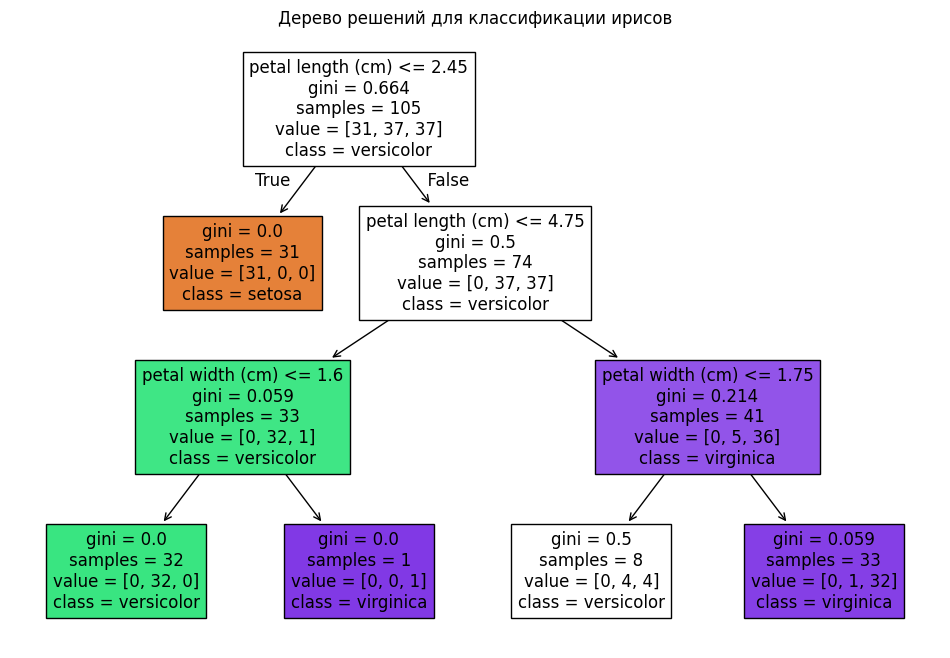


=== АНСАМБЛЕВЫЕ МЕТОДЫ ===
Точность случайного леса: 1.0000
Точность градиентного бустинга: 1.0000

=== ЛИНЕЙНЫЕ И ПОЛИНОМИАЛЬНЫЕ ПРЕОБРАЗОВАНИЯ ===
MSE линейной регрессии: 0.1091
MSE полиномиальной регрессии (degree=2): 0.0943
MSE полиномиальной регрессии (degree=3): 0.0876

=== СРАВНЕНИЕ МОДЕЛЕЙ КЛАССИФИКАЦИИ ===
Logistic Regression: 1.0000
Decision Tree: 1.0000
Random Forest: 1.0000
Gradient Boosting: 1.0000


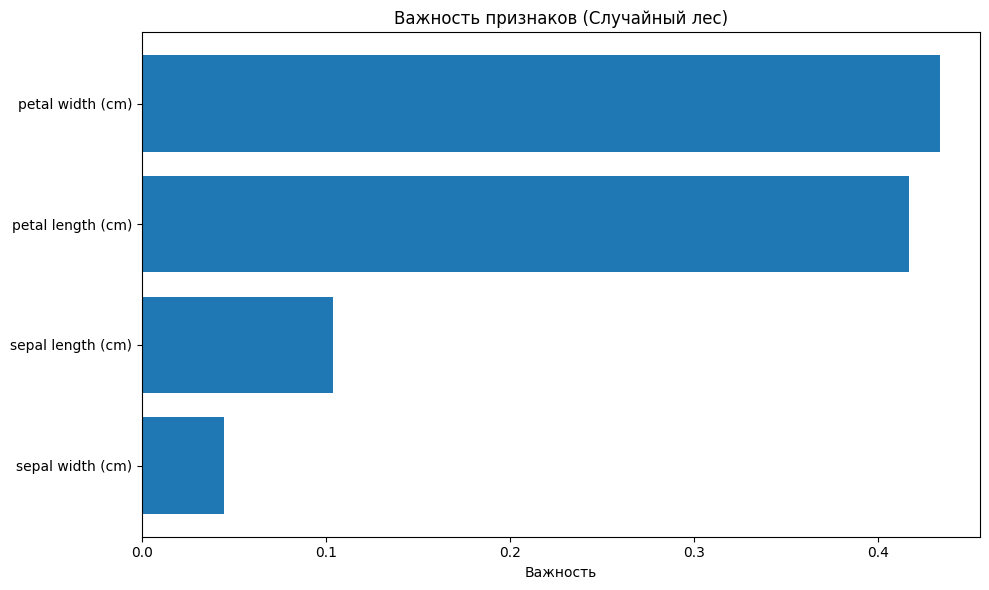

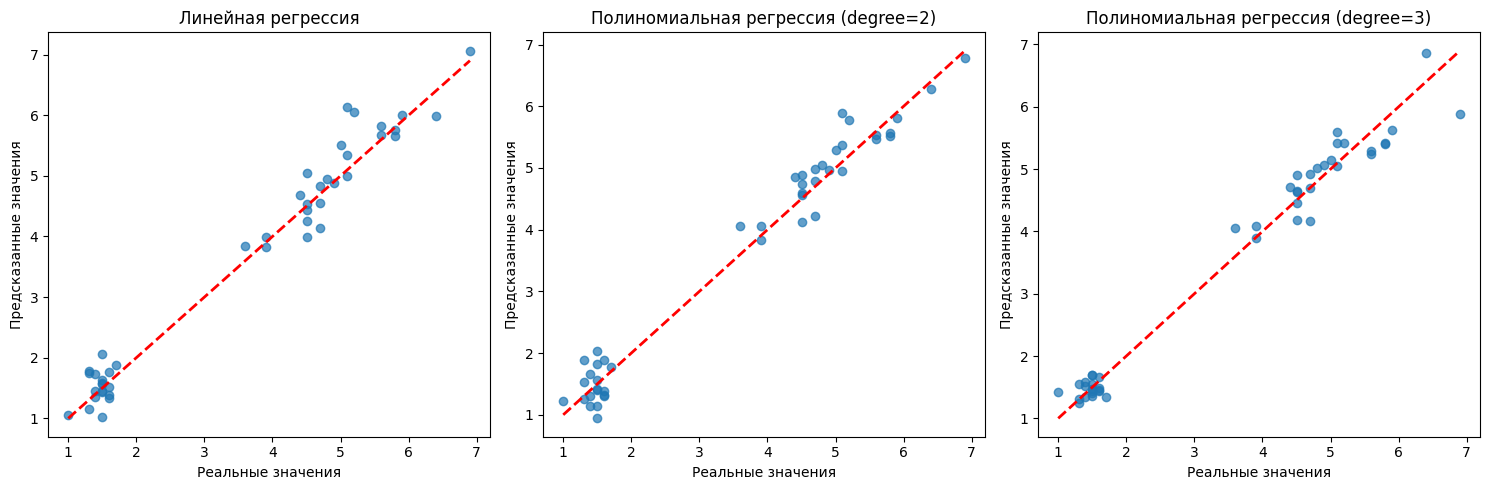

In [19]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, PolynomialFeatures # poly regression
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt
import seaborn as sns

# Загрузка данных
iris = load_iris()
df_iris = pd.DataFrame(
    data=np.hstack([iris.data, iris.target.reshape(-1,1)]), 
    columns=iris.feature_names + ['species']
)

# Разделение на признаки и целевую переменную
X = df_iris.drop('species', axis=1)
y = df_iris['species']

# Разделение на тренировочную и тестовую выборки
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Масштабирование признаков
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("=== ЛОГИСТИЧЕСКАЯ РЕГРЕССИЯ ===")
# Линейная логистическая регрессия
log_reg = LogisticRegression(multi_class='multinomial', max_iter=1000)
log_reg.fit(X_train_scaled, y_train)
y_pred_log = log_reg.predict(X_test_scaled)
print(f"Точность логистической регрессии: {accuracy_score(y_test, y_pred_log):.4f}")

print("\n=== ОДИНОЧНЫЕ ДЕРЕВЬЯ ===")
# Дерево решений
tree_clf = DecisionTreeClassifier(max_depth=3, random_state=42)
tree_clf.fit(X_train, y_train)
y_pred_tree = tree_clf.predict(X_test)
print(f"Точность дерева решений: {accuracy_score(y_test, y_pred_tree):.4f}")

# Визуализация дерева
from sklearn.tree import plot_tree
plt.figure(figsize=(12, 8))
plot_tree(tree_clf, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.title("Дерево решений для классификации ирисов")
plt.show()

print("\n=== АНСАМБЛЕВЫЕ МЕТОДЫ ===")
# Случайный лес
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42)
rf_clf.fit(X_train, y_train)
y_pred_rf = rf_clf.predict(X_test)
print(f"Точность случайного леса: {accuracy_score(y_test, y_pred_rf):.4f}")

# Градиентный бустинг
gb_clf = GradientBoostingClassifier(n_estimators=100, random_state=42)
gb_clf.fit(X_train, y_train)
y_pred_gb = gb_clf.predict(X_test)
print(f"Точность градиентного бустинга: {accuracy_score(y_test, y_pred_gb):.4f}")

print("\n=== ЛИНЕЙНЫЕ И ПОЛИНОМИАЛЬНЫЕ ПРЕОБРАЗОВАНИЯ ===")
# Линейная модель с исходными признаками
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Для регрессии будем предсказывать длину лепестка по другим признакам
X_reg = df_iris[['sepal length (cm)', 'sepal width (cm)', 'petal width (cm)']]
y_reg = df_iris['petal length (cm)']

X_train_reg, X_test_reg, y_train_reg, y_test_reg = train_test_split(X_reg, y_reg, test_size=0.3, random_state=42)

# Линейная регрессия
lin_reg = LinearRegression()
lin_reg.fit(X_train_reg, y_train_reg)
y_pred_lin = lin_reg.predict(X_test_reg)
mse_lin = mean_squared_error(y_test_reg, y_pred_lin)
print(f"MSE линейной регрессии: {mse_lin:.4f}")

# Полиномиальная регрессия 2-й степени
poly = PolynomialFeatures(degree=2, include_bias=False)
X_train_poly = poly.fit_transform(X_train_reg)
X_test_poly = poly.transform(X_test_reg)

poly_reg = LinearRegression()
poly_reg.fit(X_train_poly, y_train_reg)
y_pred_poly = poly_reg.predict(X_test_poly)
mse_poly = mean_squared_error(y_test_reg, y_pred_poly)
print(f"MSE полиномиальной регрессии (degree=2): {mse_poly:.4f}")

# Полиномиальная регрессия 3-й степени
poly3 = PolynomialFeatures(degree=3, include_bias=False)
X_train_poly3 = poly3.fit_transform(X_train_reg)
X_test_poly3 = poly3.transform(X_test_reg)

poly_reg3 = LinearRegression()
poly_reg3.fit(X_train_poly3, y_train_reg)
y_pred_poly3 = poly_reg3.predict(X_test_poly3)
mse_poly3 = mean_squared_error(y_test_reg, y_pred_poly3)
print(f"MSE полиномиальной регрессии (degree=3): {mse_poly3:.4f}")

print("\n=== СРАВНЕНИЕ МОДЕЛЕЙ КЛАССИФИКАЦИИ ===")
models = {
    'Logistic Regression': y_pred_log,
    'Decision Tree': y_pred_tree,
    'Random Forest': y_pred_rf,
    'Gradient Boosting': y_pred_gb
}

for name, pred in models.items():
    acc = accuracy_score(y_test, pred)
    print(f"{name}: {acc:.4f}")

# Визуализация важности признаков для случайного леса
plt.figure(figsize=(10, 6))
feature_importance = pd.DataFrame({
    'feature': iris.feature_names,
    'importance': rf_clf.feature_importances_
}).sort_values('importance', ascending=True)

plt.barh(feature_importance['feature'], feature_importance['importance'])
plt.title('Важность признаков (Случайный лес)')
plt.xlabel('Важность')
plt.tight_layout()
plt.show()

# Сравнение реальных и предсказанных значений для регрессии
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.scatter(y_test_reg, y_pred_lin, alpha=0.7)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.xlabel('Реальные значения')
plt.ylabel('Предсказанные значения')
plt.title('Линейная регрессия')

plt.subplot(1, 3, 2)
plt.scatter(y_test_reg, y_pred_poly, alpha=0.7)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.xlabel('Реальные значения')
plt.ylabel('Предсказанные значения')
plt.title('Полиномиальная регрессия (degree=2)')

plt.subplot(1, 3, 3)
plt.scatter(y_test_reg, y_pred_poly3, alpha=0.7)
plt.plot([y_test_reg.min(), y_test_reg.max()], [y_test_reg.min(), y_test_reg.max()], 'r--', lw=2)
plt.xlabel('Реальные значения')
plt.ylabel('Предсказанные значения')
plt.title('Полиномиальная регрессия (degree=3)')

plt.tight_layout()
plt.show()

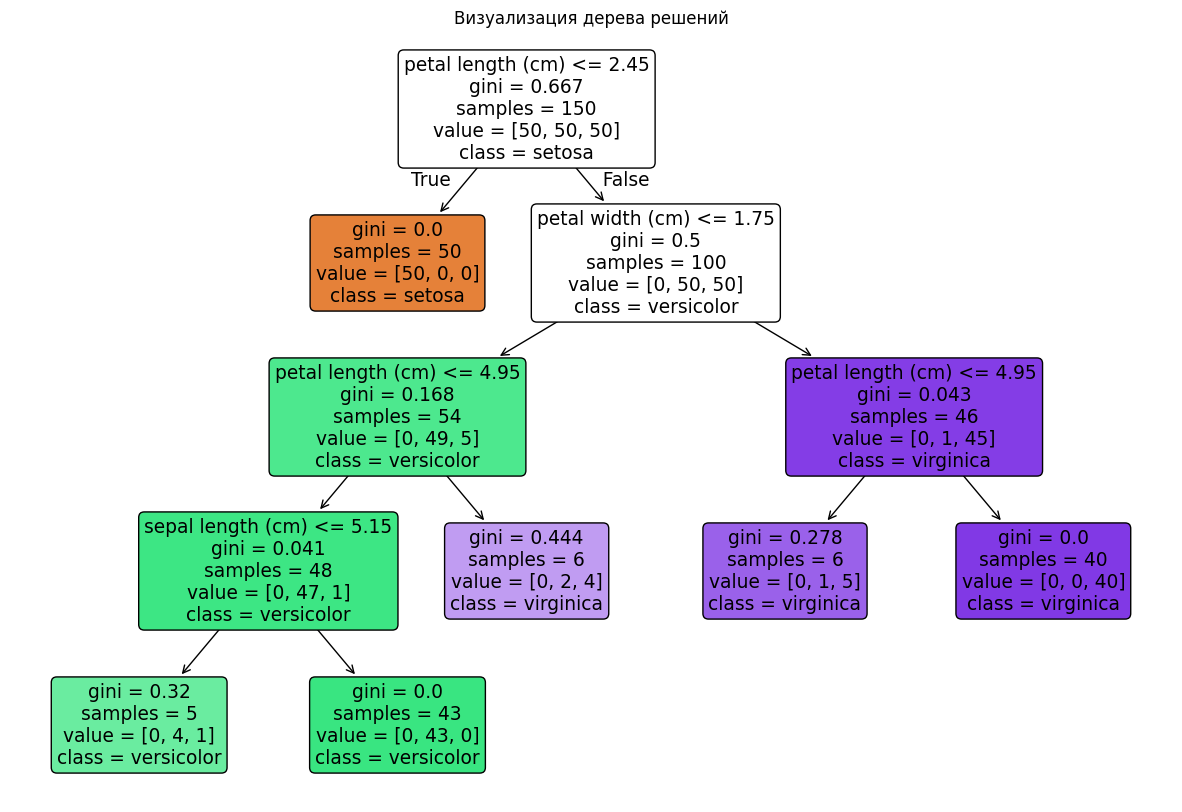

In [20]:
# from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
import numpy as np

# Загружаем данные
iris = load_iris()
X, y = iris.data, iris.target

# Обучаем модель
tree_model = DecisionTreeClassifier(
    max_depth=5,           # максимальная глубина
    min_samples_split=10,  # минимальное число samples для разделения
    min_samples_leaf=5,    # минимальное число samples в листе
    random_state=42
)
tree_model.fit(X, y)

# Визуализируем дерево
plt.figure(figsize=(15, 10))
plot_tree(tree_model, 
          feature_names=iris.feature_names,
          class_names=iris.target_names,
          filled=True,
          rounded=True)
plt.title("Визуализация дерева решений")
plt.show()


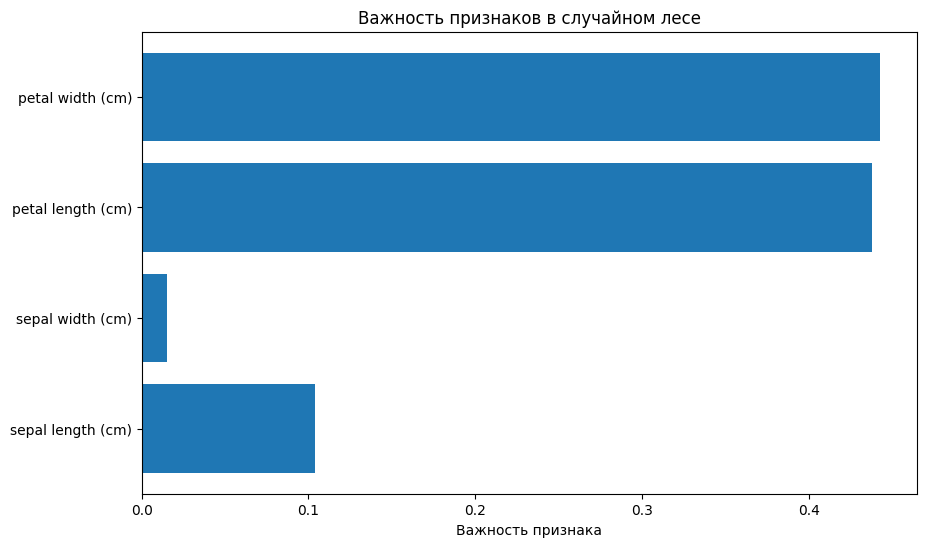

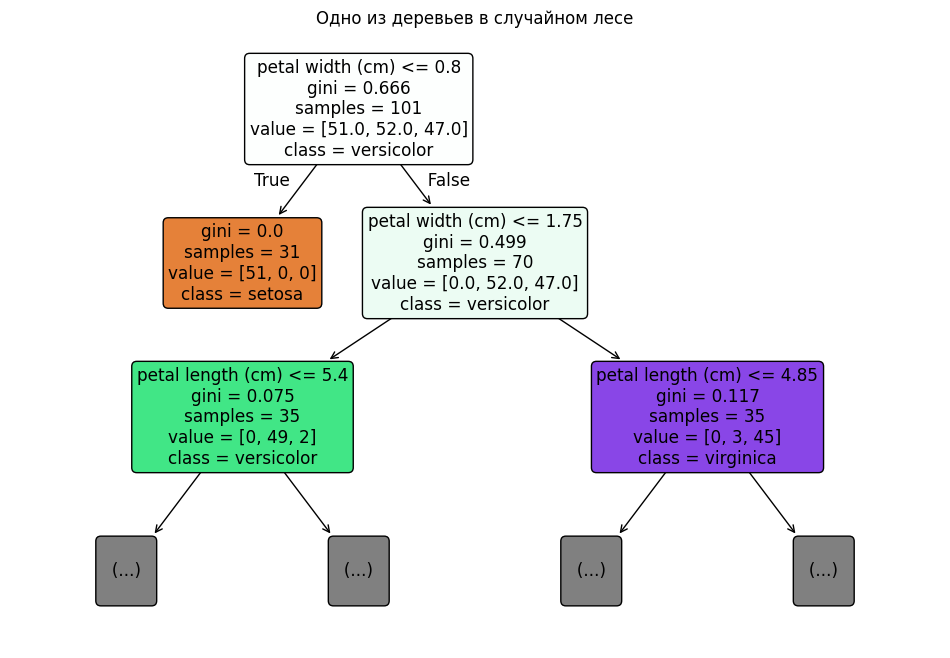

In [21]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance

# Обучаем лес
forest_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=4,
    random_state=42
)
forest_model.fit(X, y)

# Важность признаков
feature_importance = forest_model.feature_importances_
features = iris.feature_names

# График важности признаков
plt.figure(figsize=(10, 6))
plt.barh(features, feature_importance)
plt.xlabel('Важность признака')
plt.title('Важность признаков в случайном лесе')
plt.show()

# Дополнительно: визуализация одного дерева из леса
plt.figure(figsize=(12, 8))
plot_tree(forest_model.estimators_[0], 
          feature_names=iris.feature_names,
          class_names=iris.target_names,
          filled=True,
          rounded=True,
          max_depth=2)  # Показываем только 2 уровня для наглядности
plt.title("Одно из деревьев в случайном лесе")
plt.show()

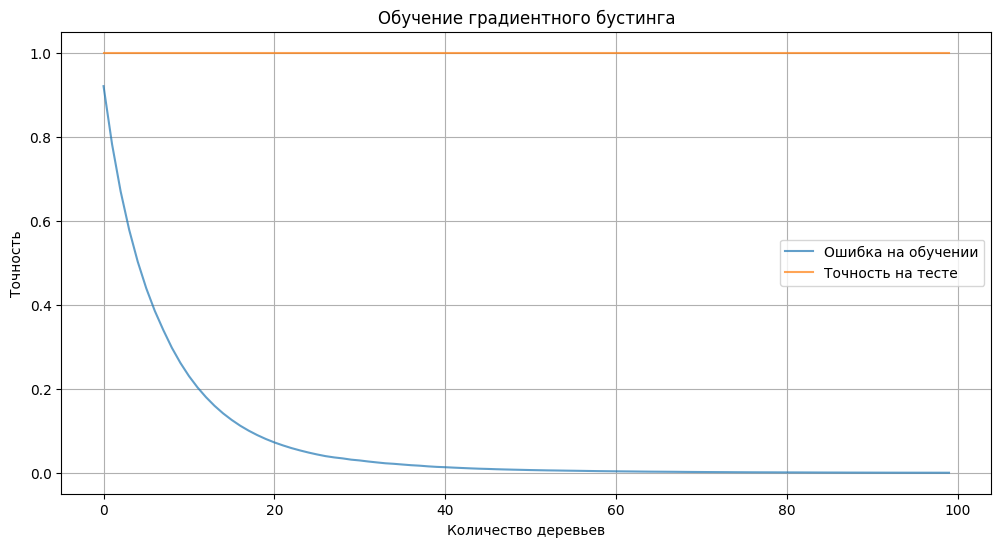

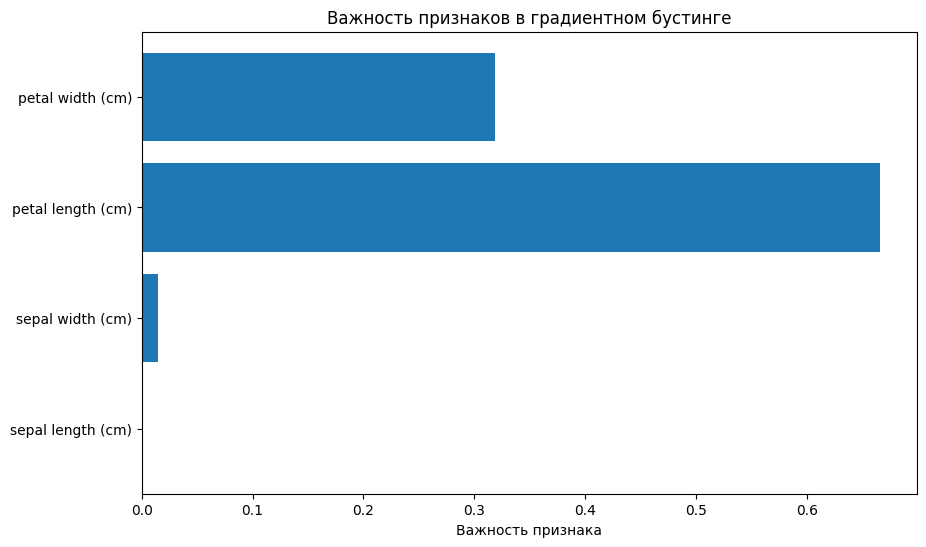

In [22]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import train_test_split

# Разделяем данные
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Обучаем бустинг
boost_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
boost_model.fit(X_train, y_train)

# График обучения (ошибка на каждой итерации)
train_scores = boost_model.train_score_
test_scores = []
for i, y_pred in enumerate(boost_model.staged_predict(X_test)):
    test_scores.append(np.mean(y_pred == y_test))

plt.figure(figsize=(12, 6))
plt.plot(train_scores, label='Ошибка на обучении', alpha=0.7)
plt.plot(test_scores, label='Точность на тесте', alpha=0.7)
plt.xlabel('Количество деревьев')
plt.ylabel('Точность')
plt.title('Обучение градиентного бустинга')
plt.legend()
plt.grid(True)
plt.show()

# График важности признаков
plt.figure(figsize=(10, 6))
plt.barh(iris.feature_names, boost_model.feature_importances_)
plt.xlabel('Важность признака')
plt.title('Важность признаков в градиентном бустинге')
plt.show()

Соберем все в датафрейм:

In [23]:
import pandas as pd
import numpy  as np

from sklearn.datasets import load_iris


# просто загрузим ирисы в датафрейм
iris = load_iris()
df_iris = pd.DataFrame(
    data=np.hstack([iris.data, iris.target.reshape(-1,1)]), 
    columns=iris.feature_names + ['species']
)
df_iris.head()

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0


И отрисуем как признаки зависят друг от друга

Три оттенка фиолетового - это наши три класса

Можем увидеть как фичи выделяются в явные кластеры, по которым можно отделять класс друг от друга

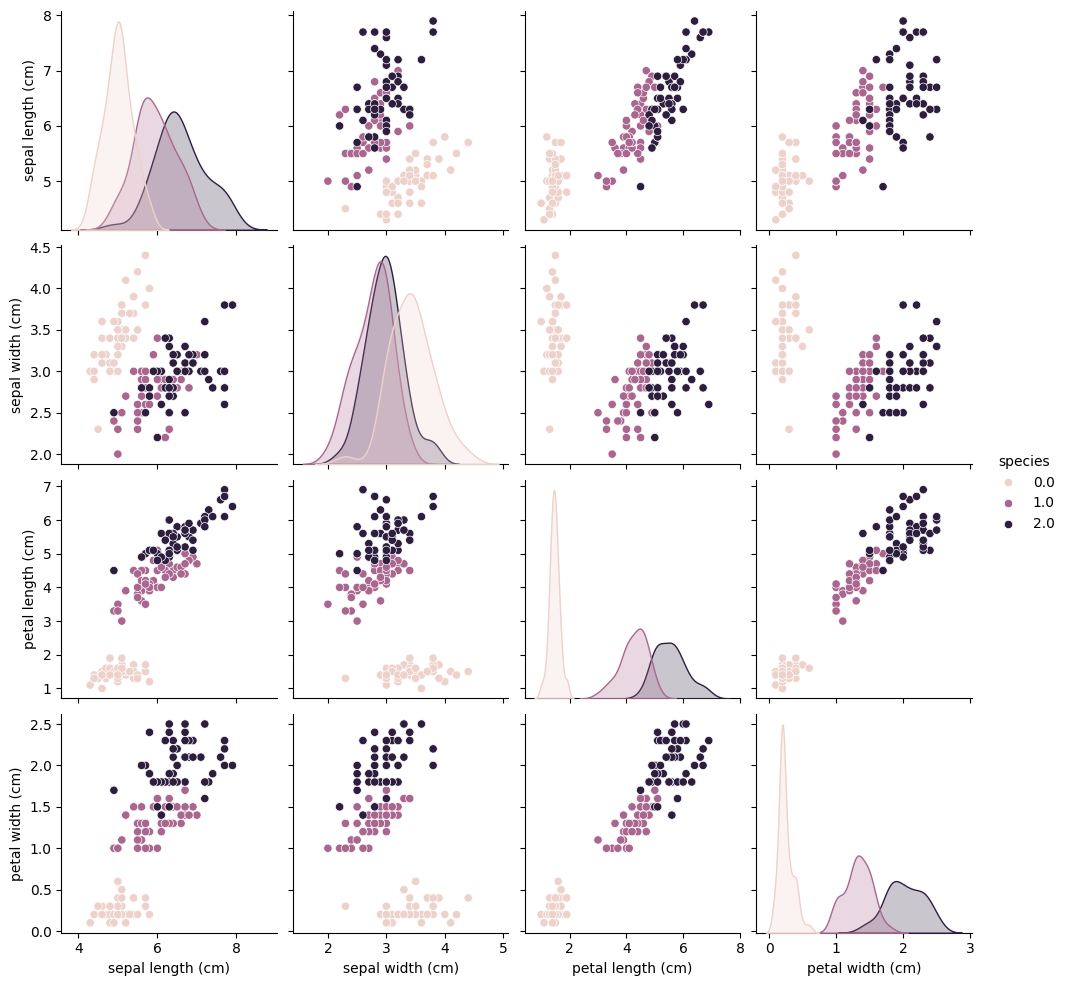

In [24]:
import seaborn as sns
sns.pairplot(df_iris, hue="species", diag_kind="kde")

Теперь пробуем построить дерево

Это  просто страшная штука для рисования графиков, можно ее пропустить

(Если все же хотите порисовать деревья, нужно поставить этот пакет)
* Linux `sudo apt-get install graphviz`
* Macos `brew install graphviz`
* Win качать [тут](https://graphviz.org/download/), если питон ругается, что не может найти файлы, то см. [тут](https://stackoverflow.com/a/20458620)

In [25]:
import matplotlib.pyplot as plt
from sklearn.tree import export_graphviz
from subprocess import call

def create_tree_image(clf):
    export_graphviz(
        clf,
        out_file='tree.dot',
        feature_names = iris.feature_names,
        class_names = iris.target_names,
        rounded = True,
        proportion = False, 
        precision = 2, 
        filled = True
    )
    call(['dot', '-Tpng', 'tree.dot', '-o', 'tree.png', '-Gdpi=600'])

    # Display in python
    plt.figure(figsize = (10, 10))
    plt.imshow(plt.imread('tree.png'))
    plt.axis('off');
    plt.show()

## дерево поболбше

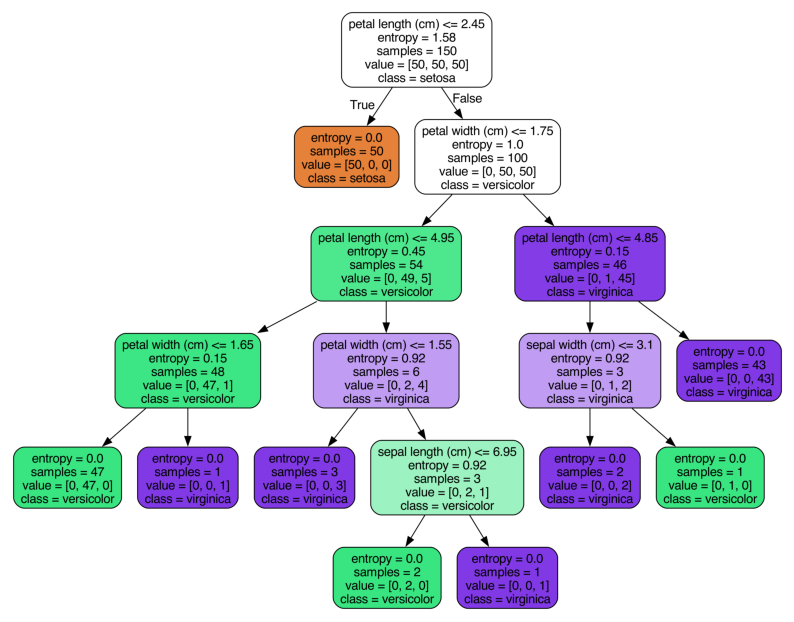

In [ ]:
dt = DecisionTreeClassifier(criterion='entropy', max_depth=6)
dt.fit(iris.data, iris.target)
create_tree_image(dt)

## Как строить?

- Найдём признак, разбиение по которому на 2 подгруппы будет наилучшим.
- Повторим для каждой из групп
- Остановимся, когда улучшение будет "небольшим" или дерево достаточно глубоким

## Как искать эти разбиения?

**Идея:**

Один загадывает знаменитость, а второй пытается отгадать, задавая только вопросы, на которые можно ответить "Да" или "Нет". 

Какой вопрос отгадывающий задаст первым делом? Тот, который сильнее всего уменьшит количество оставшихся вариантов. К примеру, вопрос "Это Анджелина Джоли?" в случае отрицательного ответа оставит более миллиона вариантов для дальнейшего перебора, а вот вопрос "Это женщина?" отсечет уже около половины знаменитостей. 

То есть, признак "пол" намного лучше разделяет выборку людей, чем признак "это Анджелина Джоли", "национальность-испанец" или "любит футбол". Это интуитивно соответствует понятию прироста информации, основанного на энтропии.

```html
Выбор атрибута разбиения
Разбиение должно осуществляться по определенному правилу, для которого и выбирают атрибут. Причем выбранный атрибут должен разбить множество наблюдений в узле так, чтобы результирующие подмножества содержали примеры с одинаковыми метками класса или были максимально приближены к этому. Иными словами — количество объектов из других классов в каждом из этих множеств должно быть как можно меньше.
```

## Энтропия
Энтропия Шеннона определяется для системы с $N$ возможными состояниями следующим образом:

$$\Large S = -\sum_{i=1}^{N}p_ilog_2p_i,$$

где  $p_i$ – вероятности нахождения системы в $i$-ом состоянии. Энтропия соответствует степени хаоса в системе. Чем выше энтропия, тем менее упорядочена система и наоборот. О том, почему функция, отражающая интуицию, именно такая, а не иная, можно прочесть [тут](https://en.wikipedia.org/wiki/Entropy_(information_theory)#Characterization).

<h4>Пример</h4>
Будем предсказывать цвет шарика по его координате.
<img src="https://habrastorage.org/files/c96/80a/a4b/c9680aa4babc40f4bbc8b3595e203979.png"/><br>

Здесь 9 синих шариков и 11 желтых. Если мы наудачу вытащили шарик, то он с вероятностью   $p_1=\frac{9}{20}$ будет синим и с вероятностью  $p_2=\frac{11}{20}$ – желтым. 

Значит, энтропия состояния  $S_0 = -\frac{9}{20}log_2{\frac{9}{20}}-\frac{11}{20}log_2{\frac{11}{20}} \approx 1$. 

Теперь посмотрим, как изменится энтропия, если разбить шарики на две группы – с координатой меньше либо равной 12 и больше 12.
<img src="https://habrastorage.org/files/186/444/a8b/186444a8bd0e451c8324ca8529f8d4f4.png"/><br>

В левой группе оказалось 13 шаров, из которых 8 синих и 5 желтых. Энтропия этой группы равна $S_1 = -\frac{5}{13}log_2{\frac{5}{13}}-\frac{8}{13}log_2{\frac{8}{13}} \approx 0.96$. 

В правой группе оказалось 7 шаров, из которых 1 синий и 6 желтых. Энтропия правой группы равна $S_2 = -\frac{1}{7}log_2{\frac{1}{7}}-\frac{6}{7}log_2{\frac{6}{7}} \approx 0.6$. 

Как видим, энтропия уменьшилась в обеих группах по сравнению с начальным состоянием, хоть в левой и не сильно. Поскольку энтропия – по сути степень хаоса (или неопределенности) в системе, **уменьшение энтропии** называют **приростом информации**. Формально прирост информации **(information gain, IG)** при разбиении выборки по признаку $Q$ (в нашем примере это признак "$x \leq 12$") определяется как 

$$\Large IG(Q) = S_O - \frac{N_1}{N}S_1 - \frac{N_2}{N}S_2,$$

где  $N_i$ – число элементов в группе $S_i$ - энтропия в группе. В нашем случае после разделения получилось две группы– одна из 13 элементов ($N_1 = 13$), вторая – из 7 ($N_2 = 7$). Прирост информации получился 

$$\Large IG("x \leq 12") = S_0 - \frac{13}{20}S_1 - \frac{7}{20}S_2 \approx 0.16.$$

Получается, разделив шарики на две группы по признаку "координата меньше либо равна 12", мы уже получили более упорядоченную систему, чем в начале. Продолжим деление шариков на группы до тех пор, пока в каждой группе шарики не будут одного цвета.  
<img src="https://habrastorage.org/files/dae/a88/2b0/daea882b0a8e4ef4b23325c88f0353a1.png"/><br>

In [ ]:
from sklearn.tree import DecisionTreeClassifier
DecisionTreeClassifier(max_depth=10)

DecisionTreeClassifier(max_depth=10)

## Переобучение

Если доводим дерево **до конца**, мы получаем дерево идеально подстроившееся под конкретную выборку, что может плохо работать на произвольных данных. Чтобы такого не происходило, используют отсечение по количеству листов (`max_leaf_nodes`),по глубине дерева (`max_depth`)  и др.

## Алгоритм построения дерева


Дерево строится **жадно**: на каждом шаге выбирается тот признак, при разделении по которому **прирост информации** оказывается наибольшим. Дальше процедура повторяется рекурсивно, пока энтропия не окажется равной нулю или какой-то малой величине.

```python
def _build_tree(self, X, y, depth):
    split_feature, split_value = self.find_best_split(X, y)

    left_inds = X[:, split_feature] <= split_value
    right_inds = X[:, split_feature] > split_value

    left_tree = self._build_tree(X[left_inds], y[left_inds], depth + 1)
    right_tree = self._build_tree(X[right_inds], y[right_inds], depth + 1)
    
    return {'val': (split_feature, split_value), 'leaf': False,
            'left': left_tree, 'right': right_tree}
```


## Answer 

мы построили дерево. 

Нам приходит новый элемент, мы use if находим подходящую ему группу, а дальше что?

Как получить ответ алгоритма из группы?

Давайте отдавать просто самый популярный класс в группе

А если нужно отдавать вероятности? Подумайте


## Основные параметры дерева

Основные параметры класса [sklearn.tree.DecisionTreeClassifier](http://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html):

- `max_depth` – максимальная глубина дерева
- `max_features` - максимальное число признаков, по которым ищется лучшее разбиение в дереве (это нужно потому, что при большом количестве признаков будет "дорого" искать лучшее (по критерию типа прироста информации) разбиение среди *всех* признаков)
- `min_samples_leaf` – минимальное число объектов в листе. У этого параметра есть понятная интерпретация: скажем, если он равен 5, то дерево будет порождать только те классифицирующие правила, которые верны как мимимум для 5 объектов

Параметры у деревьев зависят от входных данных, обычно так работает в кросс валидации


## Дерево решений в задаче регрессии
 
 При прогнозировании количественного признака идея построения остается та же, но меняется критерий качества: 

### Дисперсия в машинном обучении (ML) — это изменчивость прогноза модели для разных наборов данных. Она показывает, насколько сильно меняется прогноз модели при незначительном изменении данных. 
 
 - Дисперсия вокруг среднего: $$\Large D = \frac{1}{\ell} \sum\limits_{i =1}^{\ell} (y_i -  \overline{y})^2, \overline{y} = \frac{1}{\ell} \sum\limits_{j=1}^{\ell} y_{j}$$
 где $\ell$ – число объектов в листе, $y_i$ – значения целевого признака. Попросту говоря, минимизируя дисперсию вокруг среднего, мы ищем признаки, разбивающие выборку таким образом, что значения таргета в каждом листе примерно равны.

#### Пример
Сгенерируем данные, распределенные вокруг функции $f(x) = e^{-x ^ 2} + 1.5 * e^{-(x - 2) ^ 2}$ c некоторым шумом.

In [27]:
import numpy as np

n_train = 150        
n_test = 1000       
noise = 0.1

def f(x):
    x = x.ravel()
    return np.exp(-x ** 2) + 1.5 * np.exp(-(x - 2) ** 2)

def generate(n_samples, noise):
    X = np.random.rand(n_samples) * 10 - 5
    X = np.sort(X).ravel()
    y = np.exp(-X ** 2) + 1.5 * np.exp(-(X - 2) ** 2) + \
        np.random.normal(0.0, noise, n_samples)
    X = X.reshape((n_samples, 1))

    return X, y

X_train, y_train = generate(n_samples=n_train, noise=noise)
X_test, y_test = generate(n_samples=n_test, noise=noise)

фит предикт

In [28]:
from sklearn.tree import DecisionTreeRegressor
     
reg_tree = DecisionTreeRegressor(max_depth=4, random_state=17, criterion="absolute_error")
reg_tree.fit(X_train, y_train)
reg_tree_pred = reg_tree.predict(X_test)

страшный код для красивого графика

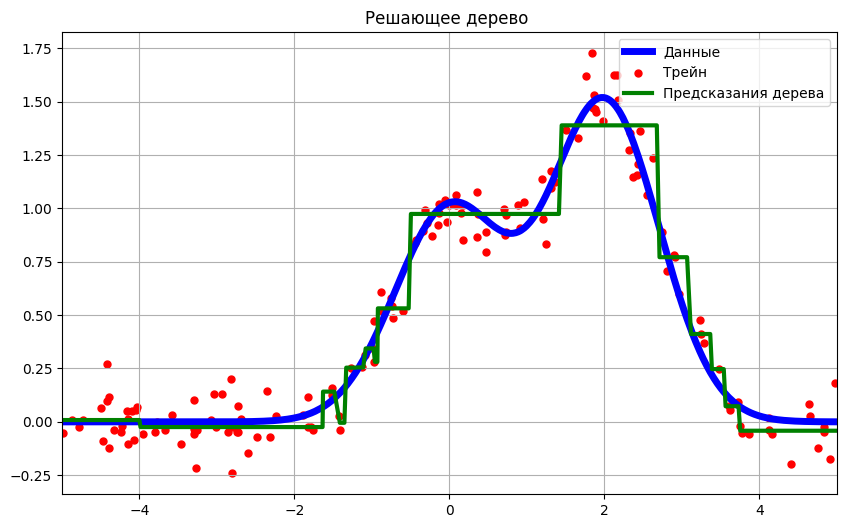

In [29]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(X_test, f(X_test), "b", lw=5, label='Данные')
plt.scatter(X_train, y_train, c="r", s=25, label='Трейн')
plt.plot(X_test, reg_tree_pred, "g", lw=3, label='Предсказания дерева')
plt.xlim([-5, 5])
plt.title("Решающее дерево " )
plt.grid()
plt.legend()
plt.show()

Видим, что дерево решений аппроксимирует зависимость в данных кусочно-постоянной функцией. 

Это означает, что прогнозирующая функция дерева делит всё пространство признаков на непересекающиеся прямоугольники, каждый из которых соответствует своему листу дерева. В каждом прямоугольнике предсказывается некоторое константное значение целевой переменной.